# 感知器 Perceptron（1958）

- **核心原理**：線性分界、錯誤驅動更新
- **推薦資料集**：Iris（只取兩類）


### 資料與探索性資料分析

In [3]:
# Load data
from ml_dl_llm.data import load_iris_binary

X_train, X_test, y_train, y_test = load_iris_binary()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

train = X_train.assign(label=y_train)

<class 'pandas.DataFrame'>
Index: 80 entries, 15 to 25
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  80 non-null     float64
 1   sepal width (cm)   80 non-null     float64
 2   petal length (cm)  80 non-null     float64
 3   petal width (cm)   80 non-null     float64
dtypes: float64(4)
memory usage: 3.1 KB


In [ ]:
# 80筆資料、全部都是連續型資料
X_train.info()

<class 'pandas.DataFrame'>
Index: 80 entries, 15 to 25
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  80 non-null     float64
 1   sepal width (cm)   80 non-null     float64
 2   petal length (cm)  80 non-null     float64
 3   petal width (cm)   80 non-null     float64
dtypes: float64(4)
memory usage: 3.1 KB


In [ ]:
# 平衡樣本
y_train.value_counts()

target
0    40
1    40
Name: count, dtype: int64

In [ ]:
# 特徵範圍
# petal length 的雖然平均較小但是變異很大
# sepal length 平均較大但是變異很小
# 兩者的 width 都沒什麼特別的
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),80.0,5.4575,0.620693,4.3,5.0,5.45,5.825,7.0
sepal width (cm),80.0,3.0825,0.487509,2.0,2.8,3.00,3.400,4.4
petal length (cm),80.0,2.8650,1.435014,1.1,1.5,2.45,4.225,5.1
petal width (cm),80.0,0.7875,0.557657,0.1,0.2,0.80,1.300,1.8


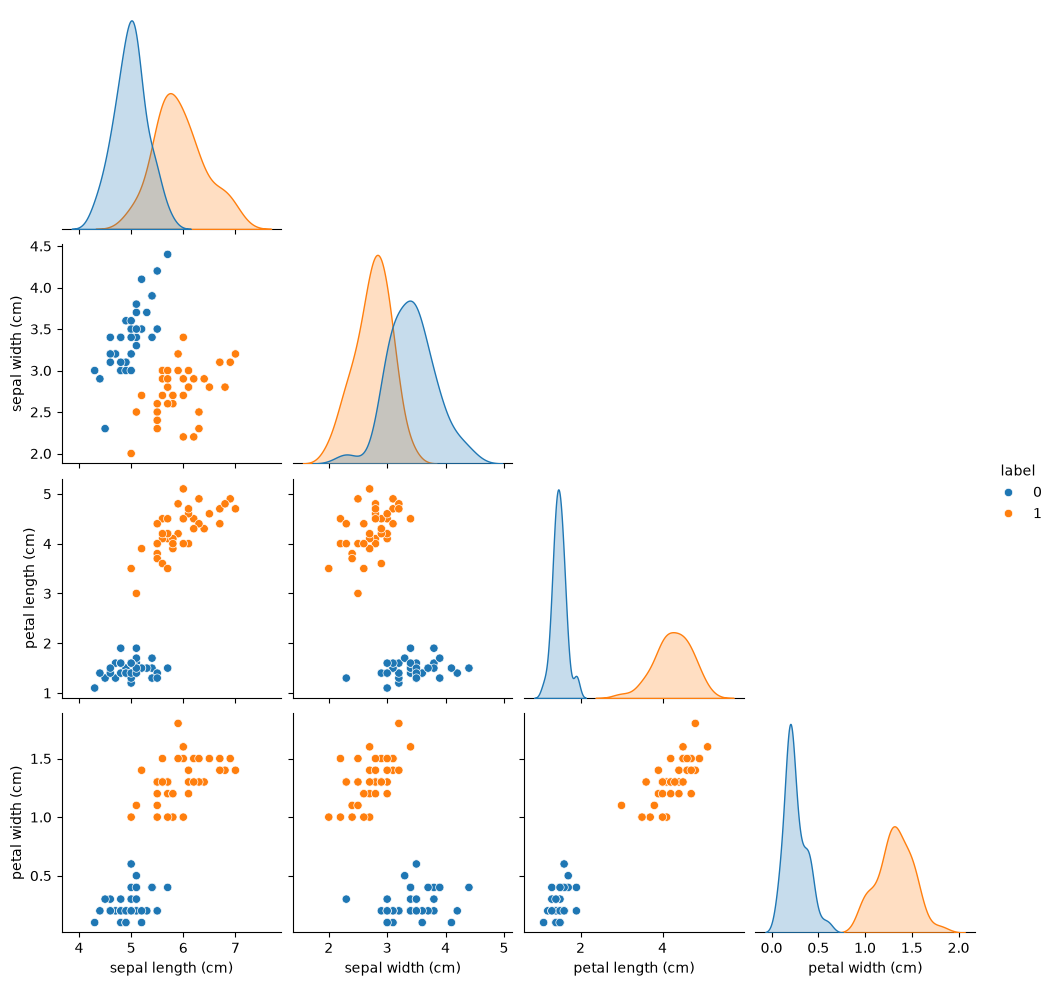

In [ ]:
# 線性可分性
# 完全線性可分
sns.pairplot(train, hue="label", corner=True)
plt.show()

In [ ]:
# 基本上petal length, petal width就可以做切分了，很明顯的兩個區段
train.groupby("label").agg(["min", "max"]).T

label                    0    1
sepal length (cm) min  4.3  5.0
                  max  5.7  7.0
sepal width (cm)  min  2.3  2.0
                  max  4.4  3.4
petal length (cm) min  1.1  3.0
                  max  1.9  5.1
petal width (cm)  min  0.1  1.0
                  max  0.6  1.8

### 手寫

In [25]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from ml_dl_llm.data import load_iris_binary

# 取出帶有標籤的資料
X_train, X_test, y_train, y_test = load_iris_binary(signed=True)

# 訓練集標準化
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)


# 感知機
class Perceptron:
    def __init__(self, lr=1.0, max_epochs=100, seed=42):
        self.lr = lr
        self.max_epochs = max_epochs
        self.seed = seed

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        n_row, n_column = X.shape
        self.w_ = np.zeros(n_column)
        self.b_ = 0.0
        self.errors_ = []
        rng = np.random.default_rng(self.seed)

        for epoch in range(self.max_epochs):
            errors = 0
            for i in rng.permutation(
                n_row
            ):  # 打亂看資料的順序，避免因為資料順序性帶來參數更新收斂的速度影響
                x = X[i, :]  # 挑出第i筆資料
                score = (
                    np.dot(self.w_, x) + self.b_
                )  # 拿特徵與權重做內積加intercept當作y的預測值，若大於0則分為正類（1)，反之為負類(-1)
                if score * y[i] <= 0: # 注意要加上等於0，因為一開始權重跟intercept都是0，不加上0學不到東西
                    errors += 1
                    self.w_ += self.lr * y[i] * x
                    self.b_ += self.lr * y[i]
            self.errors_.append(errors)
            if errors == 0:
                break
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict(self, X):
        score = self.decision_function(X)
        return np.where(score >= 0, 1, -1)

# 跑模型
model = Perceptron().fit(X_train_s, y_train)
print("每個 epoch 更新次數：", model.errors_)
print("總更新次數：", sum(model.errors_))
print("epoch 數：", len(model.errors_))
print("權重 w：", model.w_)
print("訓練集預測：", (model.predict(X_train_s) == y_train).mean())

每個 epoch 更新次數： [1, 0]
總更新次數： 1
epoch 數： 2
權重 w： [ 2.1765521  -0.5831331   1.35692615  1.10527565]
訓練集預測： 1.0


In [ ]:
# 比較訓練集標準化或不標準化的表現

print("===== 不執行正規化 =====")
model_raw = Perceptron().fit(X_train, y_train)
print("每個 epoch 更新次數：", model_raw.errors_)
print("總更新次數：", sum(model_raw.errors_))
print("epoch 數：", len(model_raw.errors_))
print("權重 w：", model_raw.w_)
print("訓練集預測：", (model_raw.predict(X_train) == y_train).mean())
print("\n")

print("===== 執行正規化 =====")
model_s = Perceptron().fit(X_train_s, y_train)
print("每個 epoch 更新次數：", model_s.errors_)
print("總更新次數：", sum(model_s.errors_))
print("epoch 數：", len(model_s.errors_))
print("權重 w：", model_s.w_)
print("訓練集預測：", (model_s.predict(X_train_s) == y_train).mean())
print("\n")

===== 不執行正規化 =====
每個 epoch 更新次數： [5, 0]
總更新次數： 5
epoch 數： 2
權重 w： [-1.2 -4.2  5.1  2.3]
訓練集預測： 1.0


===== 執行正規化 =====
每個 epoch 更新次數： [1, 0]
總更新次數： 1
epoch 數： 2
權重 w： [ 2.1765521  -0.5831331   1.35692615  1.10527565]
訓練集預測： 1.0




       updates         epochs         train_acc          
          mean min max   mean min max      mean  min  max
data                                                     
raw       8.41   2  14   2.04   2   3       1.0  1.0  1.0
scaled    1.76   1   4   2.10   2   4       1.0  1.0  1.0


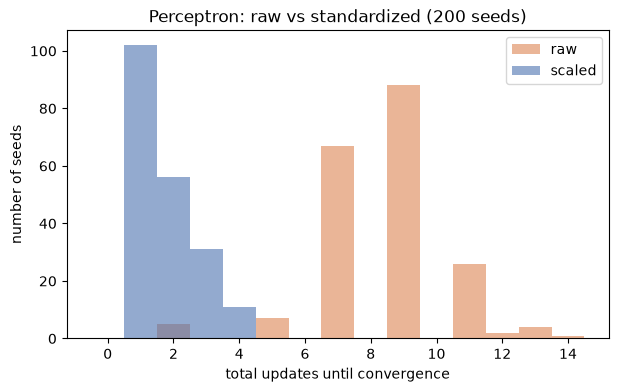

In [ ]:
# 比較不同seeds下收斂的情況
# 由圖可知不執行標準化的情況下，雖然最後都會分正確（因為資料確實完全線性可分），但會需要更新更多次才能達到收斂

import pandas as pd

seeds = range(200)
rows = []
for seed in seeds:
    for name, X in [("raw", X_train), ("scaled", X_train_s)]:
        m = Perceptron(seed=seed).fit(X, y_train)
        rows.append(
            {
                "seed": seed,
                "data": name,
                "epochs": len(m.errors_),
                "updates": sum(m.errors_),
                "train_acc": (m.predict(X) == y_train).mean(),
            }
        )

runs = pd.DataFrame(rows)

# 摘要統計：兩個版本的更新次數、epoch 數、訓練準確率
summary = runs.groupby("data")[["updates", "epochs", "train_acc"]].agg(
    ["mean", "min", "max"]
)
print(summary.round(2))

# 分布圖：總更新次數
fig, ax = plt.subplots(figsize=(7, 4))
for name, color in [("raw", "#DD8452"), ("scaled", "#4C72B0")]:
    data = runs.loc[runs["data"] == name, "updates"]
    ax.hist(
        data,
        bins=range(0, data.max() + 2),
        alpha=0.6,
        label=name,
        color=color,
        align="left",
    )
ax.set_xlabel("total updates until convergence")
ax.set_ylabel("number of seeds")
ax.set_title("Perceptron: raw vs standardized (200 seeds)")
ax.legend()
plt.show()

**觀察**：由圖可知，不執行標準化時，雖然最後都會分正確（因為資料確實完全線性可分），但需要更多次更新才能收斂（200 個 seed 平均約 8.41 次，標準化後約 1.76 次）。

原因是標準化讓資料以原點為中心、縮小了 $R$，而收斂上限是 $(R/\gamma)^2$；未標準化時資料離原點很遠，分界線主要靠每次只移動 ±1 的 bias 慢慢「搬」過去。

## 用測試集評估成績

In [34]:
from ml_dl_llm.metrics import classification_metrics
from ml_dl_llm.results import log_result

model = Perceptron(seed=42).fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)

metrics = classification_metrics(
    y_test,
    y_pred,
    y_prob=model.decision_function(X_test_s),  # 分數也可以拿來算 ROC AUC
    average="binary",  # 正類是 +1
)

log_result(
    "iris_binary",
    "Perceptron (scratch)",
    metrics,
    lr=model.lr,
    seed=model.seed,
    scaled=True,
    updates=sum(model.errors_),
)

,time,model,accuracy,precision,recall,f1,roc_auc,params,notes
0,2026-10-23 14:01,Perceptron (scratch),1.0,1.0,1.0,1.0,1.0,"{""lr"": 1.0, ""seed"": 42, ""scaled"": true, ""updat...",


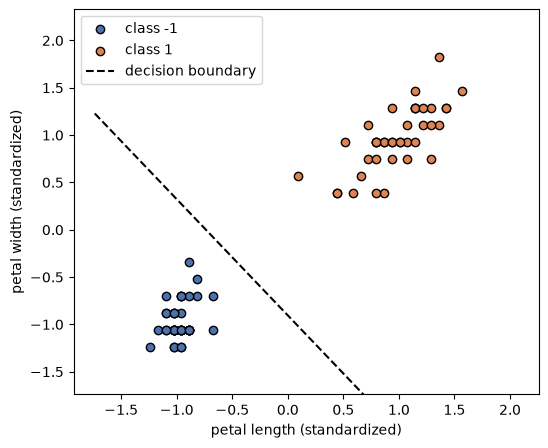

更新次數： [1, 0]


In [ ]:
# 四個特徵應該畫四維圖，但是畫不出來所以用二維去觀察就好
import numpy as np
import matplotlib.pyplot as plt

cols = [2, 3]  # petal length、petal width
X2 = X_train_s[:, cols]
m2 = Perceptron(seed=42).fit(X2, y_train)

# 分界線：w1*x1 + w2*x2 + b = 0  →  x2 = -(w1*x1 + b) / w2
w1, w2 = m2.w_
xs = np.linspace(X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5, 100)
ys = -(w1 * xs + m2.b_) / w2

fig, ax = plt.subplots(figsize=(6, 5))
for label, color in [(-1, "#4C72B0"), (1, "#DD8452")]:
    pts = X2[y_train == label]
    ax.scatter(pts[:, 0], pts[:, 1], c=color, label=f"class {label}", edgecolor="k")
ax.plot(xs, ys, "k--", label="decision boundary")
ax.set_xlabel("petal length (standardized)")
ax.set_ylabel("petal width (standardized)")
ax.set_ylim(X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5)
ax.legend()
plt.show()
print("更新次數：", m2.errors_)

# sklearn

In [37]:
from sklearn.linear_model import Perceptron as SkPerceptron
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 標準化 + 感知機綁成一個 pipeline：fit 和 predict 都會自動先標準化
sk_model = make_pipeline(StandardScaler(), SkPerceptron(random_state=42))
sk_model.fit(X_train, y_train)  # 注意：直接傳原始資料

clf = sk_model[-1]  # 取出 pipeline 最後一步（感知機本體）
print("epoch 數 n_iter_：", clf.n_iter_)
print("權重 w：", clf.coef_)
print("截距 b：", clf.intercept_)

y_pred = sk_model.predict(X_test)
metrics = classification_metrics(
    y_test, y_pred, y_prob=sk_model.decision_function(X_test), average="binary"
)
print(metrics)
log_result("iris_binary", "Perceptron (sklearn)", metrics, random_state=42)

epoch 數 n_iter_： 6
權重 w： [[ 0.87953781 -0.3767143   1.14655     1.28572882]]
截距 b： [1.]
{'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'roc_auc': 1.0}


,time,model,accuracy,precision,recall,f1,roc_auc,params,notes
0,2026-10-23 14:01,Perceptron (scratch),1.0,1.0,1.0,1.0,1.0,"{""lr"": 1.0, ""seed"": 42, ""scaled"": true, ""updat...",NaN
1,2026-10-23 14:03,Perceptron (sklearn),1.0,1.0,1.0,1.0,1.0,"{""random_state"": 42}",NaN
2,2026-10-23 14:05,Perceptron (sklearn),1.0,1.0,1.0,1.0,1.0,"{""random_state"": 42}",


---
## 本章小結

### 結果

| 模型 | 資料 | test accuracy／F1／ROC AUC | 收斂 |
| --- | --- | --- | --- |
| Perceptron（手寫） | 標準化 | 1.0 | seed 42：1 次更新、2 個 epoch |
| Perceptron（sklearn） | 標準化（Pipeline） | 1.0 | `n_iter_` = 6 |

200 個 seed 的平均總更新次數：raw ≈ 8.41、標準化 ≈ 1.76。

### 核心觀念

1. **模型**：ŷ = sign(w·x + b)，分界為超平面 w·x + b = 0；w 是超平面的法向量。
2. **錯誤驅動更新**：只在 y·(w·x + b) ≤ 0（分錯或落在線上）時更新 w ← w + η·y·x、b ← b + η·y；分對就不動。
   條件必須含「= 0」，否則初始 w = 0、b = 0 時永遠不會更新。
3. **收斂定理（Novikoff, 1962）**：資料線性可分、margin 為 γ、所有樣本 ‖x‖ ≤ R 時，更新次數 ≤ (R/γ)²，與樣本數和維度無關。
4. **標準化的作用**：讓資料以原點為中心並縮小 R；未標準化時資料離原點遠，分界線主要靠每次只動 ±η 的 bias 慢慢平移，需要更多更新。
5. **解不唯一**：只要能分開就停，不同 seed（資料順序）會得到不同的 w；感知器不追求「最好」的分界線。
6. **sklearn 的 `Perceptron`**：等價於 `SGDClassifier(loss="perceptron", learning_rate="constant", eta0=1, penalty=None)`；
   預設 `tol=1e-3`、`n_iter_no_change=5`，loss 連續 5 個 epoch 沒改善才停，所以 `n_iter_` 是 6，而不是手寫版的 2。

### 待補強（之後回來可以學）

**理論**
- [ ] 手推 Novikoff 收斂定理的證明（兩個不等式：w·w* 線性成長、‖w‖² 至多線性成長）
- [ ] 實際算出本資料的 R 與 γ（用 SVM 求最大 margin 的 w*），驗證 (R/γ)² 上限與實際更新次數的差距
- [ ] 學習率不重要：w、b 從 0 開始時，η 只會等比例縮放 w 和 b，sign 與更新序列完全相同 —— 用不同 lr 跑一次驗證
- [ ] 感知器 = 對 loss max(0, −y·(w·x + b)) 做 SGD；與 hinge loss（SVM）、log loss（邏輯回歸）比較三者的 loss 曲線
- [ ] 幾何 margin：|w·x + b| / ‖w‖；`decision_function` 是未正規化的分數，不是機率（要機率 → 邏輯回歸）

**線性不可分的情況**
- [ ] 換成 versicolor vs virginica（`load_iris_binary(labels=(1, 2))`）：觀察 errors_ 不會歸零、w 來回震盪
- [ ] Pocket algorithm：保留目前錯誤最少的 w
- [ ] Averaged perceptron／Voted perceptron：平均所有歷史 w，泛化較穩定
- [ ] XOR 問題與 Minsky & Papert（1969）：單層感知器的極限 → 多層感知器（MLP）與反向傳播的動機

**延伸**
- [ ] 不同 seed 畫出多條分界線疊在一起，對照 SVM 的最大 margin 分界線
- [ ] 多類別感知器：one-vs-rest，或對每類各一組 w、取分數最大者（用 Iris 三類）
- [ ] Kernel perceptron（對偶形式：w = Σ αᵢ yᵢ xᵢ，只用內積）→ 銜接 SVM 的 kernel trick
- [ ] Online learning：資料逐筆到來時的更新與 mistake bound

**評估方式**
- [ ] 測試集只有 20 筆、且 setosa vs versicolor 太容易分，accuracy = 1.0 資訊量很低；改用交叉驗證，或換成較難的類別組合再比較
- [ ] 手寫版與 sklearn 版係數不同的原因：資料順序、停止條件、sklearn 用 0／1 標籤而手寫用 −1／+1
